# Viz discriminator: did the v1.1 coupling fix move the needle?

Generator **v1.1** (branch `aim-coupling`, pinned sha `e802ff70`) targeted attribute-structure coupling: three
homophily groups (school / hometown / location), each with its own `attr_edge_pair` measurement, multi-channel
rewiring, and an `attr_degree` share of 0.35 over 4 bins. It improved its target metrics (homophily `gap_lift`,
per the branch). This notebook asks the stricter question: does the real-vs-fake discriminator
(`viz_discriminator.ipynb`, `snap/reports/discriminator_v1.md`) care?

The v1.1 run is the **identical pipeline** - same sampler, featurizer, config and seeds, graph_aim variants only
(no baselines; the v1 baselines and the real-vs-real controls at 0.515 / 0.528 are reused as reference, they are
the same real graph). Two new diagnostics ran at eps = inf (fold 0, gbm) on **both** versions side by side: every
attribute feature as its own permutation group, and attribute *subgroups* by statistic type and by column.

Provenance: 21 v1.1 synthetic graphs generated in the `aim-coupling` worktree and validated; seeds 1-2 of each
variant are not committed to git. Results: `snap/eval/results_v1_1/` against `snap/eval/results/` (v1). The honest
framing from v1 stands: detectability is a fidelity statement at walk level, not a privacy failure, and with the
AUC saturated near 1.0 the information is in the permutation importance, not the AUC.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display

NB = Path.cwd()
EVAL = NB.parent if NB.name == "notebooks" else NB          # snap/eval
R1 = EVAL / "results"          # v1 (snap/reports/discriminator_v1.md)
R2 = EVAL / "results_v1_1"     # v1.1 (aim-coupling, e802ff70)

plt.rcParams["figure.dpi"] = 110


def show(fig):
    display(fig)
    plt.close(fig)


summary = {"v1": pd.read_csv(R1 / "discriminator_summary.csv"), "v1.1": pd.read_csv(R2 / "discriminator_summary.csv")}
importance = {"v1": pd.read_csv(R1 / "discriminator_importance.csv"), "v1.1": pd.read_csv(R2 / "discriminator_importance.csv")}
subgroups = pd.read_csv(R2 / "discriminator_importance_subgroups_epsinf.csv")   # both versions, eps=inf, fold 0, gbm
perfeature = pd.read_csv(R2 / "discriminator_importance_perfeature_epsinf.csv") # both versions, eps=inf, fold 0, gbm

VC = {"v1": "#0072B2", "v1.1": "#D55E00"}  # fixed colour per version
BASELINES = ["erdos_renyi", "chung_lu", "dc_sbm", "bter"]
rvr = {m: summary["v1"].query("method == 'real_vs_real' and model == @m")["auc_mean"].iloc[0] for m in ("logreg", "gbm")}

for v, s in summary.items():
    g = s.query("model == 'gbm' and method == 'graph_aim'").sort_values("epsilon")
    for _, r in g.iterrows():
        print(f"{v:5s} graph_aim eps {r.epsilon!s:5s} gbm AUC {r.auc_mean:.4f} +- {r.auc_std:.4f}")
    n = s.query("model == 'gbm' and method == 'graph_aim_nocap_nonprivate'").iloc[0]
    print(f"{v:5s} no-cap non-private  gbm AUC {n.auc_mean:.4f} +- {n.auc_std:.4f}")

v1    graph_aim eps 0.5   gbm AUC 0.9999 +- 0.0002
v1    graph_aim eps 1.0   gbm AUC 0.9999 +- 0.0001
v1    graph_aim eps 2.0   gbm AUC 0.9994 +- 0.0009
v1    graph_aim eps 4.0   gbm AUC 0.9998 +- 0.0001
v1    graph_aim eps 8.0   gbm AUC 0.9999 +- 0.0001
v1    graph_aim eps inf   gbm AUC 0.9999 +- 0.0001
v1    no-cap non-private  gbm AUC 0.9999 +- 0.0000
v1.1  graph_aim eps 0.5   gbm AUC 0.9997 +- 0.0004
v1.1  graph_aim eps 1.0   gbm AUC 0.9999 +- 0.0001
v1.1  graph_aim eps 2.0   gbm AUC 0.9999 +- 0.0000
v1.1  graph_aim eps 4.0   gbm AUC 0.9961 +- 0.0066
v1.1  graph_aim eps 8.0   gbm AUC 0.9997 +- 0.0002
v1.1  graph_aim eps inf   gbm AUC 0.9997 +- 0.0001
v1.1  no-cap non-private  gbm AUC 0.9996 +- 0.0004


## 1. AUC against epsilon, v1 against v1.1

Same panels as `viz_discriminator.ipynb`: raw AUC on a linear axis (left) and **1 - AUC on a log axis** (right,
gbm everywhere; lower = more detectable). Gray triangles are the v1 baselines, the dashed black line the
real-vs-real control. *Look for:* does the orange v1.1 curve drop below the blue v1 curve anywhere?

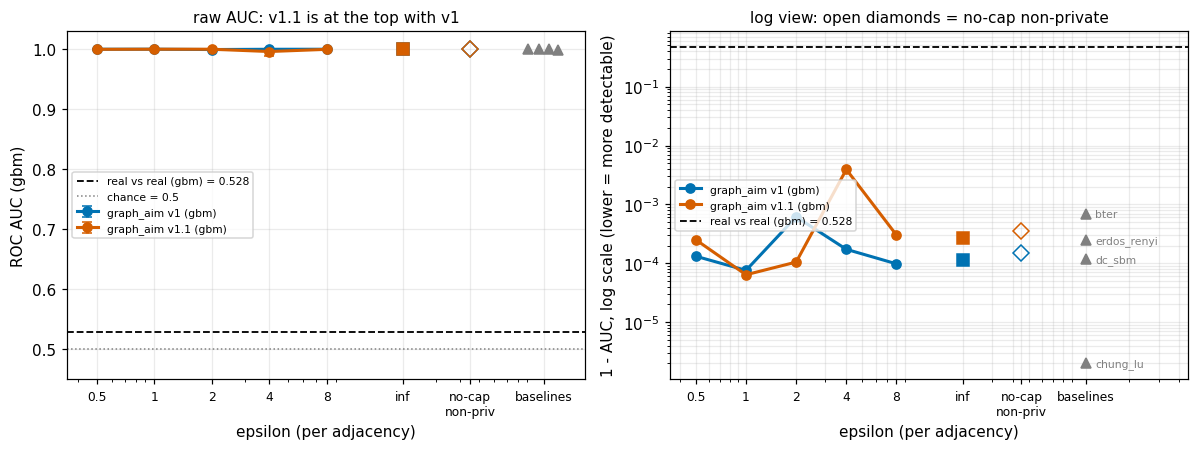

In [2]:
FIN = [0.5, 1.0, 2.0, 4.0, 8.0]
X_INF, X_NOCAP, X_BASE = 20.0, 45.0, 110.0
XTICKS = FIN + [X_INF, X_NOCAP, X_BASE]
XLABELS = ["0.5", "1", "2", "4", "8", "inf", "no-cap\nnon-priv", "baselines"]


def gbm_rows(v, method):
    d = summary[v].query("model == 'gbm' and method == @method")
    fin = d[np.isfinite(d.epsilon)].sort_values("epsilon")
    inf = d[np.isinf(d.epsilon)]
    return fin, (inf.iloc[0] if len(inf) else None)


fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.2))

for v in ("v1", "v1.1"):
    fin, inf_row = gbm_rows(v, "graph_aim")
    nocap = summary[v].query("model == 'gbm' and method == 'graph_aim_nocap_nonprivate'").iloc[0]
    ax.errorbar(fin.epsilon, fin.auc_mean, yerr=fin.auc_std, color=VC[v], lw=2, marker="o", ms=6, capsize=3,
                label=f"graph_aim {v} (gbm)")
    ax.plot([X_INF], [inf_row.auc_mean], "s", ms=8, color=VC[v])
    ax.plot([X_NOCAP], [nocap.auc_mean], "D", ms=7, mfc="none", color=VC[v])
    bx.plot(fin.epsilon, 1 - fin.auc_mean, color=VC[v], lw=2, marker="o", ms=6, label=f"graph_aim {v} (gbm)")
    bx.plot([X_INF], [1 - inf_row.auc_mean], "s", ms=8, color=VC[v])
    bx.plot([X_NOCAP], [1 - nocap.auc_mean], "D", ms=7, mfc="none", color=VC[v])

base = summary["v1"].query("model == 'gbm' and method in @BASELINES")
for i, (_, r) in enumerate(base.iterrows()):
    ax.plot([X_BASE * (1 + 0.12 * (i - 1.5))], [r.auc_mean], "^", ms=7, color="gray")
    bx.plot([X_BASE], [1 - r.auc_mean], "^", ms=7, color="gray")
    bx.annotate(r.method, (X_BASE, 1 - r.auc_mean), xytext=(6, -2), textcoords="offset points", fontsize=7, color="gray")

for p, yline in ((ax, rvr["gbm"]), (bx, 1 - rvr["gbm"])):
    p.axhline(yline, color="black", ls="--", lw=1.2, label=f"real vs real (gbm) = {rvr['gbm']:.3f}")
ax.axhline(0.5, color="gray", ls=":", lw=1, label="chance = 0.5")

ax.set_xscale("log")
ax.set_xticks(XTICKS, XLABELS, fontsize=8)
ax.set_xlim(0.35, 180)
ax.set_ylim(0.45, 1.03)
ax.set_xlabel("epsilon (per adjacency)")
ax.set_ylabel("ROC AUC (gbm)")
ax.set_title("raw AUC: v1.1 is at the top with v1", fontsize=10)
ax.legend(fontsize=7, loc="center left")
ax.grid(alpha=0.25)

bx.set_xscale("log")
bx.set_yscale("log")
bx.set_xticks(XTICKS, XLABELS, fontsize=8)
bx.set_xlim(0.35, 450)
bx.set_xlabel("epsilon (per adjacency)")
bx.set_ylabel("1 - AUC, log scale (lower = more detectable)")
bx.set_title("log view: open diamonds = no-cap non-private", fontsize=10)
bx.legend(fontsize=7, loc="center left")
bx.grid(alpha=0.25, which="both")

fig.tight_layout()
show(fig)

**What we see.** v1.1 does **not** move the discriminator: gbm AUC is 0.996-0.9999 at every epsilon including
inf and the no-cap non-private variant (v1: 0.9994-0.9999); logistic regression alone is 0.993-0.997 in both.
The only v1.1 point visibly off the v1 band is eps = 4, and that is one fold at 0.988 (the other two are 0.9999)
- fold noise, not a trend. Both versions stay roughly four orders of magnitude below the real-vs-real control on
the log panel. The coupling fix improved its target metrics but not walk-level detectability.

## 2. Attributes importance across epsilon, v1 against v1.1

Permutation importance of the whole **attributes** group (solid) and of **degree** (dashed, second-largest) for
the gbm, overlaid for the two generator versions. With the AUC saturated, this is where an improvement would show:
a lower attributes curve would mean less attribute signal to read.

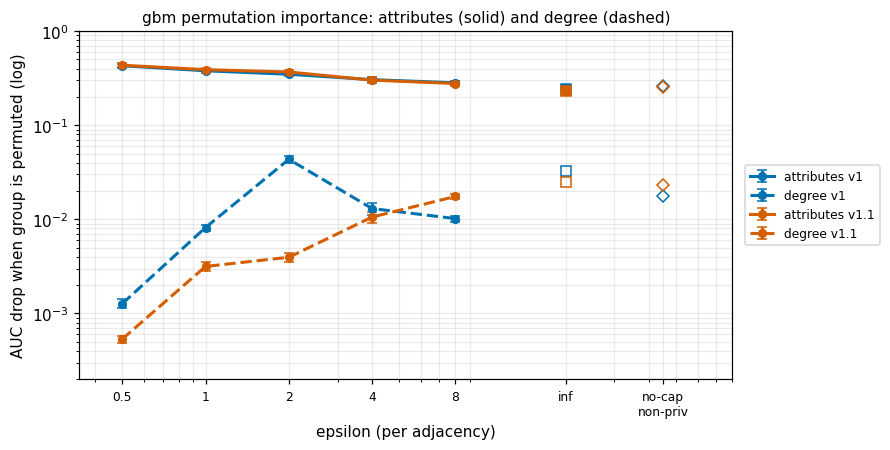

In [3]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))
for v in ("v1", "v1.1"):
    imp = importance[v].query("method == 'graph_aim'")
    for g, ls in (("attributes", "-"), ("degree", "--")):
        d = imp.query("group == @g")
        dfin = d[np.isfinite(d.epsilon)].sort_values("epsilon")
        dinf = d[np.isinf(d.epsilon)].iloc[0]
        ax.errorbar(dfin.epsilon, dfin.auc_drop, yerr=dfin.auc_drop_std, color=VC[v], ls=ls, lw=2,
                    marker="o", ms=5, capsize=3, label=f"{g} {v}")
        ax.plot([X_INF], [dinf.auc_drop], "s", ms=7, color=VC[v], mfc="none" if g == "degree" else VC[v])
        nc = importance[v].query("method == 'graph_aim_nocap_nonprivate' and group == @g").iloc[0]
        ax.plot([X_NOCAP], [nc.auc_drop], "D", ms=6, mfc="none", color=VC[v])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([*FIN, X_INF, X_NOCAP], ["0.5", "1", "2", "4", "8", "inf", "no-cap\nnon-priv"], fontsize=8)
ax.set_xlim(0.35, 80)
ax.set_ylim(2e-4, 1)
ax.set_xlabel("epsilon (per adjacency)")
ax.set_ylabel("AUC drop when group is permuted (log)")
ax.set_title("gbm permutation importance: attributes (solid) and degree (dashed)", fontsize=10)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
show(fig)

**What we see.** The attributes curves lie on top of each other: 0.43 at eps 0.5 falling monotonically to 0.23 at
inf for v1.1, against 0.43 to 0.24 for v1 - unchanged within the fold noise. Degree stays a distant second in
both. The epsilon gradient is still real and still entirely inside the attributes group; v1.1 did not shrink it.

## 3. Inside the attributes group: subgroups at eps = inf

New diagnostic (eps = inf, fold 0, gbm, both versions): the attributes group split into *subgroups* - by statistic
type (`type:share` = per-value marginal shares, `type:none_other` = `none`/`other` shares, `type:same_edge_rate`,
`type:pair_edge_match` = attribute-pair co-occurrence on edges) and by column (`share_col:<attribute>` = all share
features of one attribute). `attributes_all` is the whole group for scale. Log axis; drops within noise of zero
are clipped to 1e-6.

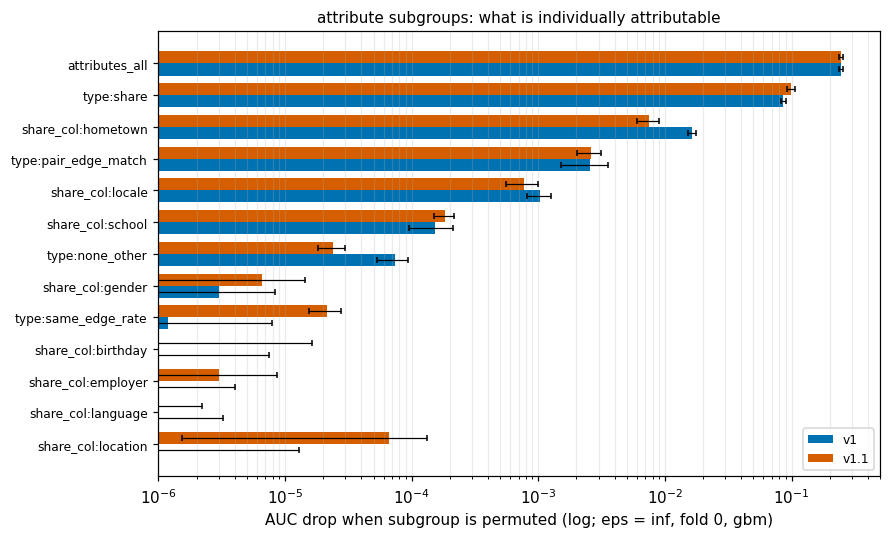

,v1,v1.1
group,,
attributes_all,0.24460,0.24468
type:share,0.08632,0.09941
share_col:hometown,0.01642,0.00747
type:pair_edge_match,0.00254,0.00259
share_col:locale,0.00103,0.00078
share_col:school,0.00015,0.00018
type:none_other,0.00007,0.00002
share_col:gender,0.00000,0.00001
type:same_edge_rate,0.00000,0.00002


In [4]:
FLOOR = 1e-6
order = (subgroups.query("version == 'v1'").set_index("group").auc_drop
         .reindex(subgroups.group.unique()).sort_values().index.tolist())

fig, ax = plt.subplots(figsize=(8.2, 5))
y = np.arange(len(order))
h = 0.38
for off, (v, key) in zip((-h / 2, h / 2), (("v1", "v1"), ("v1.1", "v1_1"))):
    d = subgroups.query("version == @key").set_index("group").reindex(order)
    ax.barh(y + off, d.auc_drop.clip(lower=FLOOR), height=h, color=VC[v], label=v,
            xerr=d.auc_drop_std, error_kw=dict(lw=0.8, capsize=2))
ax.set_yticks(y, order, fontsize=8)
ax.set_xscale("log")
ax.set_xlim(FLOOR, 0.5)
ax.set_xlabel("AUC drop when subgroup is permuted (log; eps = inf, fold 0, gbm)")
ax.set_title("attribute subgroups: what is individually attributable", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.25, axis="x", which="both")
fig.tight_layout()
show(fig)

sub = subgroups.pivot(index="group", columns="version", values="auc_drop").loc[order[::-1]].round(5)
sub.columns = ["v1", "v1.1"]
display(sub)

**What we see.**

- `type:share` dominates what is individually attributable (0.086 in v1, 0.099 in v1.1): the per-value marginal
  shares *inside a walk*.
- `share_col:hometown` is the strongest single column and the one visible v1.1 improvement: 0.0164 to 0.0075.
  Hometown is one of the three coupled homophily groups, so the fix did reach the walk level there - it just does
  not matter for the AUC.
- **The suspected `none`/`other` generation artifact is refuted**: `type:none_other` drops only 7e-5 (v1) / 2e-5
  (v1.1). The open point from `docs/realfake/snap.md` section 2 (issue 1 in `docs/realfake/PROCESS.md`) closes:
  the attribute signal is genuine statistics, not a representation artifact.
- `type:same_edge_rate` is ~0 and `type:pair_edge_match` only ~0.0026 in both: the classifier is *not* mainly
  reading homophily edge rates.

Note the subgroup drops do not add up to `attributes_all` (0.24 in both versions) - see the next section.

## 4. Per feature: no single giveaway

The same diagnostic with *every* attribute feature as its own permutation group (degree and structure kept as
whole groups for scale). Top 10 per version:

In [5]:
tops = []
for key, v in (("v1", "v1"), ("v1_1", "v1.1")):
    d = (perfeature.query("version == @key").sort_values("auc_drop", ascending=False)
         .head(10)[["group", "auc_drop"]].round(5).reset_index(drop=True))
    d.columns = pd.MultiIndex.from_product([[v], ["feature / group", "auc_drop"]])
    tops.append(d)
is_attr = perfeature.group.str.startswith("attributes:")
attr_max = {v: perfeature[is_attr & (perfeature.version == k)].auc_drop.max()
            for v, k in (("v1", "v1"), ("v1.1", "v1_1"))}
print(f"largest single-attribute-feature drop: v1 {attr_max['v1']:.4f}, v1.1 {attr_max['v1.1']:.4f} "
      f"- against 0.24 for the whole attributes group in both")
pd.concat(tops, axis=1)

largest single-attribute-feature drop: v1 0.0012, v1.1 0.0005 - against 0.24 for the whole attributes group in both


v1           \
                            feature / group auc_drop   
0                                    degree  0.03380   
1                                 structure  0.00811   
2    attributes:share:hometown=hometown_935  0.00117   
3        attributes:share:locale=locale_278  0.00053   
4  attributes:pair_edge_match:locale|school  0.00036   
5    attributes:share:hometown=hometown_908  0.00019   
6     attributes:share:hometown=hometown_84  0.00015   
7              attributes:share:school=none  0.00009   
8  attributes:pair_edge_match:gender|locale  0.00007   
9        attributes:share:locale=locale_932  0.00006   

                                         v1.1           
                              feature / group auc_drop  
0                                      degree  0.02521  
1                                   structure  0.00984  
2      attributes:share:hometown=hometown_908  0.00053  
3          attributes:share:locale=locale_278  0.00038  
4      attributes:share:hometown=hometown_935  0.00031  
5          attributes:share:locale=locale_932  0.00016  
6    attributes:pair_edge_match:locale|school  0.00016  
7    attributes:pair_edge_match:gender|locale  0.00010  
8       attributes:share:location=location_84  0.00010  
9  attributes:pair_edge_match:birthday|school  0.00007

**What we see.** The attribute signal is **diffuse and redundant**: no single attribute feature costs the gbm
more than 0.0012 AUC (v1; 0.0005 in v1.1), yet permuting the whole group costs 0.24. The model reads a
distributed fingerprint over many share features at once; knock out any one - or any subgroup - and the rest
still carry it. That is also why the subgroup drops above do not add up to `attributes_all`.

## Interpretation and what v1.2 needs

The giveaway is per-walk attribute **composition**. A walk through the real graph stays inside communities, so it
sees locally concentrated value distributions (neighbours share hometown, locale, school); a walk through a
synthetic graph sees attribute mixes that mirror the global marginals. Matching global homophily edge-count tables
- even three of them, as v1.1 does - reproduces edge-level rates but does not create that local coherence, which
is why `gap_lift` improved while the discriminator did not blink. For v1.2 this points at placing attributes with
community/cluster-level coherence (attribute-aware blocks, joint attribute-community structure), not only
edge-count matching; the discriminator is the acceptance test.

Caveats: the per-feature and subgroup diagnostics are one fold at eps = inf (gbm); the AUC is saturated, so all
comparisons between versions rest on the importance, not the AUC; as before, detectability is a fidelity
statement at walk level, not a privacy failure - and a failed discriminator would have been evidence of fidelity,
not privacy.